# Preprocesado de datasets con dataprepy

**Autora:** Alazne Valencia Saez<br>
**Asignatura:** Software Matemático y Estadístico (Programación Científica)<br>
**Fecha:** noviembre de 2026

**Índice**

1. [Lectura de los datos](#1.-Lectura-de-los-datos)
2. [La clase Dataset](#2.-La-clase-Dataset)
3. [Discretización](#3.-Discretización)
4. [Métricas de las variables](#4.-Métricas-de-las-variables)
5. [Normalización y estandarización](#5.-Normalización-y-estandarización)
6. [Filtrado de variables](#6.-Filtrado-de-variables)
7. [Correlación e información mutua](#7.-Correlación-e-información-mutua)
8. [Guardar y leer datasets en formato propio](#8.-Guardar-y-leer-datasets-en-formato-propio)
9. [Decisiones de diseño](#9.-Decisiones-de-diseño)
10. [Resumen](#10.-Resumen)

## Introducción

**dataprepy** es un módulo de Python con herramientas básicas para preprocesar
bases de datos. Es la versión en Python del paquete de R **dataprepR**, con las
mismas funcionalidades. Todos los algoritmos (discretización, métricas, AUC,
entropía, información mutua, etc.) están implementados a mano: solo se usan
las operaciones básicas de Python y **numpy**, **pandas** para gestionar las
tablas de datos y **matplotlib** para los gráficos.

Las funciones del módulo se agrupan por funcionalidades. La última columna
indica el apartado de este notebook en el que se muestra cada grupo:

| Funcionalidad | Funciones | Apartado |
|:--------------|:----------|:---------|
| Discretización | `discretize`, `discretizeEW`, `discretizeEF`, `discretizeData` | 3 |
| Métricas | `entropy`, `calculateAUC`, `computeMetrics` | 4 |
| Normalización y estandarización | `normalize`, `standardize`, `normalizeData`, `standardizeData` | 5 |
| Filtrado de variables | `filterData` | 6 |
| Correlación e información mutua | `correlation`, `mutualInformation`, `computeCorrelations` | 7 |
| Visualización | `plotROC`, `plotAUC`, `plotCorrelation`, `plotEntropy` | 3.4, 4.2, 4.3 y 7 |
| Gestión de datasets | `readCSV`, `Dataset`, `isDataset`, `print`, `summary`, `writeDataset`, `readDataset` | 1, 2 y 8 |

Las funciones que trabajan con un dataset completo aceptan un `DataFrame` de
pandas, una matriz (un array de numpy de dos dimensiones) o un objeto de la
clase `Dataset` del propio módulo. En este notebook vamos a ver cómo se usa
cada una de ellas.

El módulo se instala con `pip`, desde el fichero `.whl` (o el `.tar.gz`) que
se incluye en la entrega:

```
pip install dataprepy-1.0.0-py3-none-any.whl
```

También se puede instalar desde la carpeta del código fuente con
`pip install -e .`. Una vez instalado, lo importamos junto con los módulos que
usaremos en los ejemplos:

In [1]:
import os
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import dataprepy as dp

# Para que las tablas se lean mejor, las mostramos con 4 decimales
pd.set_option("display.precision", 4)

## 1. Lectura de los datos

Como ejemplo usaremos el conjunto de datos `mtcars`, que viene con R y que se
incluye en formato CSV (`mtcars.csv`). Para ejecutar el notebook, los ficheros
`mtcars.csv` e `iris.csv` tienen que estar en la misma carpeta que él. Tiene información de 32 coches:
consumo (`mpg`), número de cilindros (`cyl`), potencia (`hp`), peso (`wt`),
tipo de motor (`vs`), tipo de cambio (`am`, 0 = automático y 1 = manual), etc.

Si leemos el fichero con `pandas.read_csv`, todas las columnas son numéricas,
aunque algunas (como `cyl` o `am`) son claramente categóricas. La función
`readCSV` del módulo mira los valores de cada columna y le asigna el tipo
adecuado: `category` si tiene menos de `max_categories` valores distintos,
entero (`int64`) si todos son enteros, real (`float64`) si son números reales
y texto en otro caso. En la tabla se comparan los tipos que se obtienen con
cada función:

In [2]:
coches = dp.readCSV("mtcars.csv", max_categories=5)

pd.DataFrame({"pandas.read_csv": pd.read_csv("mtcars.csv").dtypes,
              "dp.readCSV": coches.dtypes})

,pandas.read_csv,dp.readCSV
mpg,float64,float64
cyl,int64,category
disp,float64,float64
hp,int64,int64
drat,float64,float64
wt,float64,float64
qsec,float64,float64
vs,int64,category
am,int64,category
gear,int64,category


Las variables `cyl`, `vs`, `am` y `gear` tienen menos de 5 valores distintos y
se han leído como categóricas. `hp` y `carb` tienen más valores, pero todos
son enteros, así que se han leído como enteros. El resto son números reales.
Igual que los niveles de un factor de R, las categorías se guardan como texto:

In [3]:
coches["cyl"].cat.categories

Index(['4', '6', '8'], dtype='str')

Para que los resultados se entiendan mejor, ponemos nombres a las categorías
de la variable `am`, que usaremos como variable clase:

In [4]:
coches["am"] = coches["am"].cat.rename_categories(["automatico", "manual"])
coches["am"].value_counts(sort=False)

am
automatico    19
manual        13
Name: count, dtype: int64

La regla de `readCSV` es aproximada: una variable numérica con pocos valores
distintos se leería como categórica, y una categoría codificada con muchos
números distintos, como numérica. Las funciones del paquete trabajan con el
tipo que tiene cada columna, así que, si hace falta, se puede corregir a mano.
Por ejemplo, si leemos `mtcars` con `pandas.read_csv`, el número de cilindros
queda como un número, y para tratarlo como una variable categórica basta con
convertirlo:

In [5]:
datos = pd.read_csv("mtcars.csv")
print(datos["cyl"].dtype)
datos["cyl"] = datos["cyl"].astype("category")
print(datos["cyl"].dtype)

int64
category


## 2. La clase Dataset

Para trabajar con los datos de forma cómoda, el módulo define una clase
llamada `Dataset` que agrupa el `DataFrame` con el nombre de su variable clase
y un nombre descriptivo. Se crea como cualquier objeto de una clase de Python:

In [6]:
ds = dp.Dataset(coches, class_name="am", name="Coches (mtcars)")
dp.isDataset(ds)

True

La clase tiene definido el método especial `__str__`, que es el que usa
`print` para mostrar el objeto. Muestra un resumen de su contenido:

In [7]:
print(ds)

Objeto de clase 'Dataset'
Nombre: Coches (mtcars)
Dimensiones: 32 filas x 11 variables
Variable clase: am

Tipos de las variables:
mpg      float64
cyl     category
disp     float64
hp         int64
drat     float64
wt       float64
qsec     float64
vs      category
am      category
gear    category
carb       int64

Primeras filas:
    mpg cyl   disp   hp  drat     wt   qsec vs          am gear  carb
0  21.0   6  160.0  110  3.90  2.620  16.46  0      manual    4     4
1  21.0   6  160.0  110  3.90  2.875  17.02  0      manual    4     4
2  22.8   4  108.0   93  3.85  2.320  18.61  1      manual    4     1
3  21.4   6  258.0  110  3.08  3.215  19.44  1  automatico    3     1
4  18.7   8  360.0  175  3.15  3.440  17.02  0  automatico    3     2


Los datos, la variable clase y el nombre son los atributos `data`,
`class_name` y `name` del objeto, así que se puede acceder a ellos con un
punto. El método `getPredictorNames` devuelve las
variables que no son la clase:

In [8]:
print(ds.class_name)
print(ds.data.shape)
print(ds.getPredictorNames())

am
(32, 11)
['mpg', 'cyl', 'disp', 'hp', 'drat', 'wt', 'qsec', 'vs', 'gear', 'carb']


El tipo de cada variable es el tipo de su columna en `data`: entera o real
para las numéricas, `category` o booleana para las categóricas y texto para
las demás.

La ventaja de usar esta clase es que las funciones de preprocesado saben cuál
es la variable clase: no la transforman (no se normaliza ni se discretiza) y
la usan automáticamente cuando hace falta, por ejemplo para calcular el AUC.
Además, cuando reciben un `Dataset` devuelven un nuevo `Dataset` con la misma
clase y el mismo nombre.

## 3. Discretización

La discretización transforma una variable numérica en una categórica,
dividiendo su rango en intervalos. El módulo implementa dos algoritmos
clásicos, **igual anchura** (*equal width*) e **igual frecuencia** (*equal
frequency*). El resultado es una variable de tipo `pandas.Categorical`, que es
el equivalente en Python a un factor de R.

### 3.1. Igual anchura

En la discretización por igual anchura el rango de la variable se divide en
`num_bins` intervalos del mismo tamaño. En el siguiente ejemplo los valores
van de 0.5 a 20.5, así que con 4 intervalos la anchura es 5 y los puntos de
corte son 5.5, 10.5 y 15.5.

In [9]:
x = [11.5, 10.2, 1.2, 0.5, 5.3, 20.5, 8.4]
ew, cortes_ew = dp.discretizeEW(x, num_bins=4)
print(ew)
print("Puntos de corte:", cortes_ew)

['(10.5, 15.5]', '(5.5, 10.5]', '(-inf, 5.5]', '(-inf, 5.5]', '(-inf, 5.5]', '(15.5, inf)', '(5.5, 10.5]']
Categories (4, str): ['(-inf, 5.5]', '(5.5, 10.5]', '(10.5, 15.5]', '(15.5, inf)']
Puntos de corte: [ 5.5 10.5 15.5]


La función devuelve dos resultados (una tupla, que separamos en dos
variables): los valores discretizados y los puntos de corte. El nombre de
cada categoría indica los límites del intervalo. El primer intervalo empieza
en `-inf` y el último termina en `inf` (infinito), para que cualquier valor
nuevo tenga un intervalo asignado aunque quede fuera del rango original.

### 3.2. Igual frecuencia

En la discretización por igual frecuencia los puntos de corte se eligen para
que en cada intervalo caiga el mismo número de valores (más o menos uno). Cada
punto de corte se pone a mitad de camino entre el último valor de un intervalo
y el primero del siguiente.

In [10]:
ef, cortes_ef = dp.discretizeEF(x, num_bins=4)
print(ef)
print("Puntos de corte:", cortes_ef)

['(10.85, inf)', '(9.3, 10.85]', '(-inf, 3.25]', '(-inf, 3.25]', '(3.25, 9.3]', '(10.85, inf)', '(3.25, 9.3]']
Categories (4, str): ['(-inf, 3.25]', '(3.25, 9.3]', '(9.3, 10.85]', '(10.85, inf)']
Puntos de corte: [ 3.25  9.3  10.85]


In [11]:
pd.Series(ef).value_counts(sort=False)

(-inf, 3.25]    2
(3.25, 9.3]     2
(9.3, 10.85]    1
(10.85, inf)    2
Name: count, dtype: int64

Con 7 valores y 4 intervalos no se puede repartir exactamente, así que los
intervalos tienen 2 o 1 valores. Si comparamos con la discretización por igual
anchura se ve la diferencia: allí había 3 valores en el primer intervalo y 1 en
el tercero.

In [12]:
pd.Series(ew).value_counts(sort=False)

(-inf, 5.5]     3
(5.5, 10.5]     2
(10.5, 15.5]    1
(15.5, inf)     1
Name: count, dtype: int64

Los valores repetidos siempre van al mismo intervalo, porque un punto de corte
solo se puede poner entre dos valores distintos. Si la posición de un corte cae
entre dos valores iguales, el corte se mueve al hueco entre valores distintos
más cercano. Si por ello dos cortes acaban en el mismo sitio, la función avisa
y crea menos intervalos. Por ejemplo, si de 8 valores 5 son iguales a 1, no se
pueden hacer 4 intervalos de 2 valores:

In [13]:
repetidos, cortes_repetidos = dp.discretizeEF([1, 1, 1, 1, 1, 2, 3, 4], num_bins=4)
print("Puntos de corte:", cortes_repetidos)
pd.Series(repetidos).value_counts(sort=False)

Puntos de corte: [1.5 2.5]


C:\Users\alzor\anaconda3\Lib\site-packages\dataprepy\discretization.py:248: UserWarning: Por los valores repetidos salen menos intervalos de los pedidos
  warnings.warn("Por los valores repetidos salen menos intervalos de "


(-inf, 1.5]    5
(1.5, 2.5]     1
(2.5, inf)     2
Name: count, dtype: int64

### 3.3. Discretizar con unos puntos de corte dados

La función `discretize` aplica unos puntos de corte concretos. Es útil para
discretizar datos nuevos con los mismos intervalos que se obtuvieron con los
datos originales:

In [14]:
nuevos_valores = [-3, 5.5, 12, 100]
dp.discretize(nuevos_valores, cut_points=cortes_ew)

['(-inf, 5.5]', '(-inf, 5.5]', '(10.5, 15.5]', '(15.5, inf)']
Categories (4, str): ['(-inf, 5.5]', '(5.5, 10.5]', '(10.5, 15.5]', '(15.5, inf)']

Un valor igual a un punto de corte (el 5.5) pertenece al intervalo de su
izquierda, ya que los intervalos son de la forma (a, b].

### 3.4. Discretizar un dataset completo

`discretizeData` aplica cualquiera de los dos métodos a todas las variables
numéricas de un dataset (las categóricas se dejan igual). Con un objeto
`Dataset`, la variable clase no se toca. Empezamos por igual anchura
(`method="EW"`, el valor por defecto):

In [15]:
ds_ew, cortes_ds_ew = dp.discretizeData(ds, num_bins=3, method="EW")
ds_ew.data.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,"(18.23, 26.07]",6,"(-inf, 204.7]","(-inf, 146.3]","(3.483, 4.207]","(-inf, 2.817]","(-inf, 17.3]",0,manual,4,"(3.333, 5.667]"
1,"(18.23, 26.07]",6,"(-inf, 204.7]","(-inf, 146.3]","(3.483, 4.207]","(2.817, 4.12]","(-inf, 17.3]",0,manual,4,"(3.333, 5.667]"
2,"(18.23, 26.07]",4,"(-inf, 204.7]","(-inf, 146.3]","(3.483, 4.207]","(-inf, 2.817]","(17.3, 20.1]",1,manual,4,"(-inf, 3.333]"
3,"(18.23, 26.07]",6,"(204.7, 338.4]","(-inf, 146.3]","(-inf, 3.483]","(2.817, 4.12]","(17.3, 20.1]",1,automatico,3,"(-inf, 3.333]"
4,"(18.23, 26.07]",8,"(338.4, inf)","(146.3, 240.7]","(-inf, 3.483]","(2.817, 4.12]","(-inf, 17.3]",0,automatico,3,"(-inf, 3.333]"


Y ahora con igual frecuencia (`method="EF"`):

In [16]:
ds_disc, cortes_ds_ef = dp.discretizeData(ds, num_bins=3, method="EF")
ds_disc.data.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,"(16.85, 21.45]",6,"(145.8, 288.4]","(109.5, 177.5]","(3.18, 3.91]","(-inf, 2.827]","(-inf, 17.04]",0,manual,4,"(3.5, inf)"
1,"(16.85, 21.45]",6,"(145.8, 288.4]","(109.5, 177.5]","(3.18, 3.91]","(2.827, 3.49]","(-inf, 17.04]",0,manual,4,"(3.5, inf)"
2,"(21.45, inf)",4,"(-inf, 145.8]","(-inf, 109.5]","(3.18, 3.91]","(-inf, 2.827]","(18.56, inf)",1,manual,4,"(-inf, 1.5]"
3,"(16.85, 21.45]",6,"(145.8, 288.4]","(109.5, 177.5]","(-inf, 3.18]","(2.827, 3.49]","(18.56, inf)",1,automatico,3,"(-inf, 1.5]"
4,"(16.85, 21.45]",8,"(288.4, inf)","(109.5, 177.5]","(-inf, 3.18]","(2.827, 3.49]","(-inf, 17.04]",0,automatico,3,"(1.5, 3.5]"


Además del dataset discretizado, la función devuelve un diccionario con los
puntos de corte de cada variable, por ejemplo los de la potencia (`hp`) con
cada método:

In [17]:
print("Igual anchura:   ", cortes_ds_ew["hp"])
print("Igual frecuencia:", cortes_ds_ef["hp"])

Igual anchura:    [146.33333333 240.66666667]
Igual frecuencia: [109.5 177.5]


La diferencia entre los dos métodos se ve bien en esta variable. Con igual
anchura los tres intervalos miden lo mismo, pero como hay pocos coches muy
potentes el último intervalo tiene muy pocos valores. Con igual frecuencia,
en cambio, cada intervalo tiene más o menos el mismo número de coches:

In [18]:
print(ds_ew.data["hp"].value_counts(sort=False), "\n")
print(ds_disc.data["hp"].value_counts(sort=False))

hp
(-inf, 146.3]     17
(146.3, 240.7]    11
(240.7, inf)       4
Name: count, dtype: int64 

hp
(-inf, 109.5]     11
(109.5, 177.5]    11
(177.5, inf)      10
Name: count, dtype: int64


Una forma de ver cómo han quedado las variables categóricas es la entropía
normalizada (que veremos en el siguiente apartado), que vale 1 cuando los
valores se reparten por igual entre todos los intervalos. `plotEntropy` la
muestra en un diagrama de barras. Con igual frecuencia, las variables
discretizadas quedan muy cerca de 1. La más baja es `carb` (0.97), porque
tiene muchos valores repetidos y no se puede repartir del todo por igual: sus
intervalos tienen 7, 13 y 12 coches (ver el apartado de decisiones de
diseño). Las variables que ya eran categóricas (`cyl`, `vs`,
`am` y `gear`) no cambian:

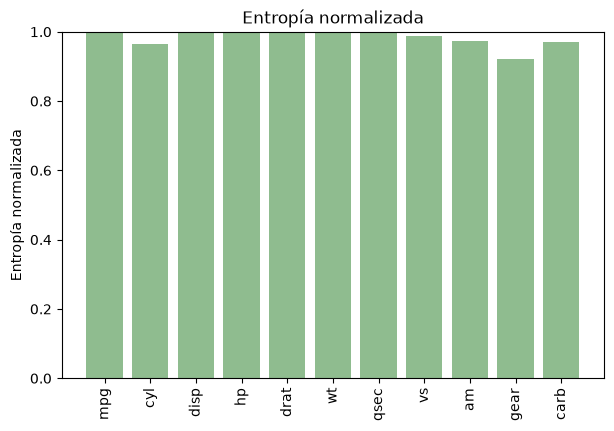

In [19]:
entropia_normalizada = dp.plotEntropy(ds_disc)

Todas las funciones de gráficos devuelven los valores que dibujan. Aquí los
hemos guardado en una variable para que no se muestren debajo del gráfico:

In [20]:
entropia_normalizada.round(3)

mpg     0.999
cyl     0.966
disp    0.999
hp      0.999
drat    0.999
wt      0.999
qsec    0.999
vs      0.989
am      0.974
gear    0.922
carb    0.971
dtype: float64

## 4. Métricas de las variables

### 4.1. Entropía

La entropía mide la incertidumbre de una variable categórica:
$H(X) = -\sum_i p_i \log_2(p_i)$, donde $p_i$ es la proporción de cada posible
valor. Por ejemplo, con los valores posibles a, b y c y los datos
a, a, c, c, c, las probabilidades son 0.4, 0 y 0.6:

In [21]:
f = pd.Categorical(["a", "a", "c", "c", "c"], categories=["a", "b", "c"])
dp.entropy(f)

0.9709505944546686

La entropía es 0 si la variable siempre toma el mismo valor y es máxima
(`log2` del número de valores) cuando todos los valores son igual de
frecuentes.

### 4.2. Curva ROC y AUC

El AUC (área bajo la curva ROC) mide lo bien que una variable numérica, por sí
sola, separa las dos clases de una variable binaria. `calculateAUC` recibe un
`DataFrame` de dos columnas: la variable y la clase.

In [22]:
auc_ejemplo = pd.DataFrame({"valor": [0.1, 0.4, 0.35, 0.8],
                            "clase": [False, False, True, True]})
puntos_roc, auc = dp.calculateAUC(auc_ejemplo)
print(puntos_roc)
print("\nAUC:", auc)

   FPR  TPR
0  0.0  0.0
1  0.0  0.5
2  0.5  0.5
3  0.5  1.0
4  1.0  1.0

AUC: 0.75


Para cada posible punto de corte (los valores de la variable), las filas con
valor mayor o igual se predicen como positivas. Comparando con la clase real se
calcula la tasa de verdaderos positivos (TPR) y la de falsos positivos (FPR),
que forman un punto de la curva. El área se calcula sumando los trapecios entre
puntos consecutivos. La clase también puede ser una variable con dos valores
que no sean `True` y `False`. En ese caso el positivo es el segundo: si es
categórica, la segunda categoría (en nuestros datos, `manual`), y si no, el
mayor de los dos valores (por ejemplo, el 1 en una variable 0/1).

`plotROC` dibuja la curva. Por ejemplo, para el consumo (`mpg`) respecto al
tipo de cambio:

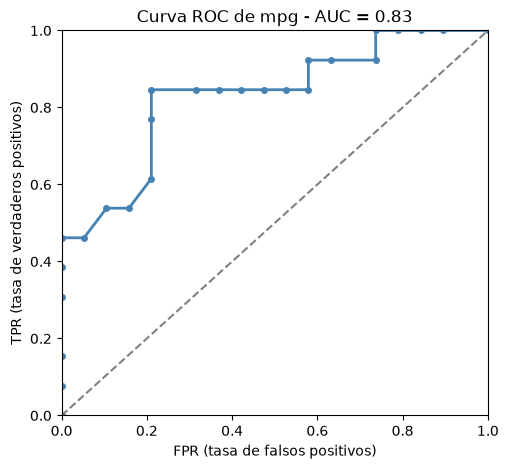

In [23]:
puntos_mpg, auc_mpg = dp.plotROC(ds.data[["mpg", "am"]], title="Curva ROC de mpg")

Y para el peso (`wt`), que tiene un AUC muy bajo. Como veremos más adelante,
eso también indica que la variable separa bien las clases, pero al revés: los
coches más pesados suelen tener cambio automático.

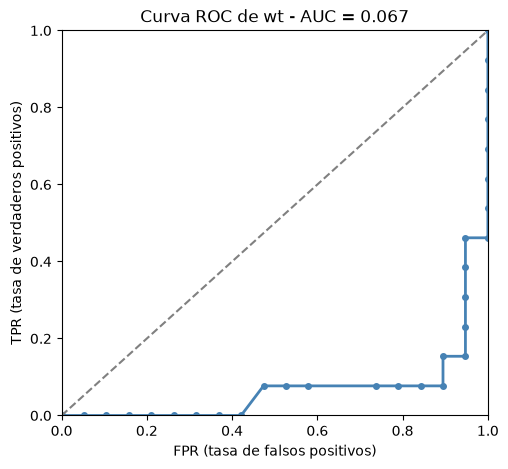

In [24]:
puntos_wt, auc_wt = dp.plotROC(ds.data[["wt", "am"]], title="Curva ROC de wt")

### 4.3. Métricas de todo el dataset

`computeMetrics` reconoce el tipo de cada variable y calcula las métricas que
le corresponden: **varianza y AUC** para las numéricas y **entropía** para las
categóricas. Las que no corresponden aparecen como `NaN`. Con un objeto
`Dataset` usa automáticamente su variable clase para el AUC:

In [25]:
metricas = dp.computeMetrics(ds)
metricas

,type,variance,auc,entropy
mpg,numeric,36.3241,0.8300,NaN
cyl,categorical,NaN,NaN,1.5310
disp,numeric,15360.7998,0.1336,NaN
hp,numeric,4700.8669,0.2874,NaN
drat,numeric,0.2859,0.9028,NaN
wt,numeric,0.9574,0.0668,NaN
qsec,numeric,3.1932,0.3806,NaN
vs,categorical,NaN,NaN,0.9887
gear,categorical,NaN,NaN,1.4615
carb,numeric,2.6089,0.4636,NaN


Con un `DataFrame` hay que indicar la clase con el argumento `class_name` (si
no se indica, no se calcula el AUC):

In [26]:
dp.computeMetrics(coches, class_name="am").head(3)

,type,variance,auc,entropy
mpg,numeric,36.3241,0.8300,NaN
cyl,categorical,NaN,NaN,1.531
disp,numeric,15360.7998,0.1336,NaN


El método `summary` de la clase `Dataset` devuelve esta misma tabla:

In [27]:
ds.summary().equals(metricas)

True

El AUC solo tiene sentido con una variable clase binaria. Si la clase tiene
más de dos valores, como `Species` en el conjunto de datos `iris`, la función
avisa y deja el AUC como `NaN`, pero calcula igualmente el resto de métricas:

In [28]:
iris = dp.readCSV("iris.csv")
dp.Dataset(iris, class_name="Species").summary()

C:\Users\alzor\anaconda3\Lib\site-packages\dataprepy\metrics.py:243: UserWarning: La variable clase 'Species' no es binaria: no se calcula el AUC
  warnings.warn(f"La variable clase '{class_name}' no es binaria: "


,type,variance,auc,entropy
Sepal.Length,numeric,0.6857,NaN,NaN
Sepal.Width,numeric,0.1900,NaN,NaN
Petal.Length,numeric,3.1163,NaN,NaN
Petal.Width,numeric,0.5810,NaN,NaN


`plotAUC` muestra el AUC de todas las variables numéricas ordenado de mayor a
menor:

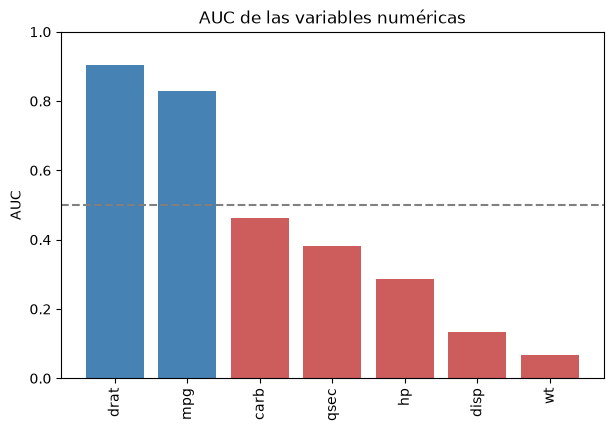

In [29]:
auc_variables = dp.plotAUC(ds)

Las variables con un AUC alto (como `drat`, 0.90, o `mpg`, 0.83) toman
valores altos en los coches con cambio manual. Las que tienen un AUC cercano a
0 (como `wt`, 0.07) también separan muy bien las clases, pero al revés: los
coches más pesados suelen ser automáticos. Las que están cerca de 0.5 (línea
discontinua) no separan las clases al ordenar sus valores. Eso no siempre
quiere decir que no tengan relación con la clase: el AUC no detecta, por
ejemplo, que los coches de una clase estén en los dos extremos de la variable.

## 5. Normalización y estandarización

La **normalización** lleva los valores al rango [0, 1] restando el mínimo y
dividiendo entre el rango. La **estandarización** resta la media y divide entre
la desviación estándar, de modo que el resultado tiene media 0 y desviación
estándar 1. Por ejemplo:

In [30]:
v = [-0.29, 2.11, -3.84, 10.69, 5.30]

v_norm = dp.normalize(v)
print("Normalizado:  ", v_norm.round(4))
print("Mínimo:", v_norm.min(), " Máximo:", v_norm.max())

v_std = dp.standardize(v)
print("\nEstandarizado:", v_std.round(4))
print("Media:", v_std.mean(), " Desviación estándar:", v_std.std(ddof=1))

Normalizado:   [0.2443 0.4095 0.     1.     0.629 ]
Mínimo: 0.0  Máximo: 1.0

Estandarizado: [-0.557  -0.1235 -1.1982  1.4261  0.4526]
Media: 5.551115123125783e-17  Desviación estándar: 1.0


La media no sale exactamente 0 sino un número del orden de $10^{-16}$, que es
0 salvo por los errores de redondeo de los números reales en el ordenador.

`normalizeData` y `standardizeData` aplican la transformación a todas las
variables numéricas de un dataset. Las variables categóricas no se modifican
y, en un objeto `Dataset`, la clase tampoco:

In [31]:
ds_norm = dp.normalizeData(ds)
ds_norm.data.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,0.4511,6,0.2218,0.2049,0.5253,0.2830,0.2333,0,manual,4,0.4286
1,0.4511,6,0.2218,0.2049,0.5253,0.3482,0.3000,0,manual,4,0.4286
2,0.5277,4,0.0920,0.1449,0.5023,0.2063,0.4893,1,manual,4,0.0000
3,0.4681,6,0.4662,0.2049,0.1475,0.4352,0.5881,1,automatico,3,0.0000
4,0.3532,8,0.7206,0.4346,0.1797,0.4927,0.3000,0,automatico,3,0.1429


Con `describe` comprobamos que todas las variables numéricas van ahora de 0 a
1:

In [32]:
numericas = ["mpg", "disp", "hp", "drat", "wt", "qsec", "carb"]
ds_norm.data[numericas].describe().loc[["min", "max"]]

,mpg,disp,hp,drat,wt,qsec,carb
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Y que, después de estandarizar, todas tienen media 0 (los valores del orden de
$10^{-16}$ son 0 salvo errores de redondeo) y desviación estándar 1:

In [33]:
ds_std = dp.standardizeData(ds)
ds_std.data[numericas].describe().loc[["mean", "std"]]

,mpg,disp,hp,drat,wt,qsec,carb
mean,-4.9960e-16,1.1102e-16,2.7756e-17,-3.0531e-16,-4.1633e-16,-1.4433e-15,2.7756e-17
std,1.0000e+00,1.0000e+00,1.0000e+00,1.0000e+00,1.0000e+00,1.0000e+00,1.0000e+00


Las variables originales tienen escalas muy distintas (por ejemplo `disp` llega
a 472 y `wt` no pasa de 5.5). Después de estandarizarlas todas son
comparables:

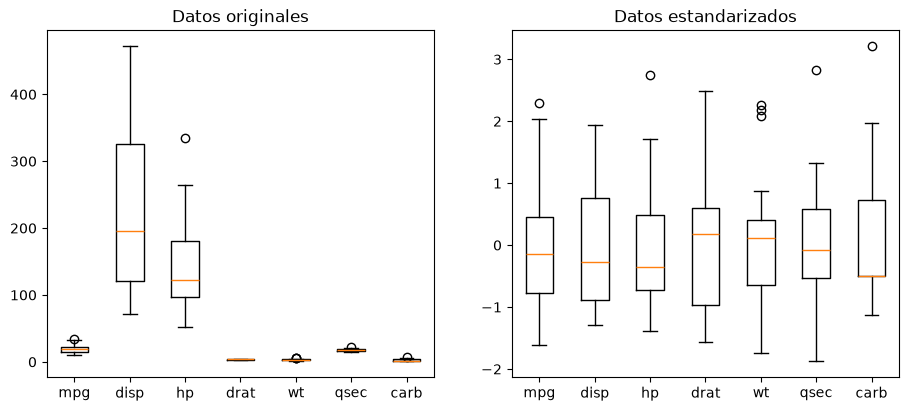

In [34]:
plt.figure(figsize=(11, 4.5))

plt.subplot(1, 2, 1)
plt.boxplot([ds.data[columna] for columna in numericas])
plt.xticks(range(1, len(numericas) + 1), numericas)
plt.title("Datos originales")

plt.subplot(1, 2, 2)
plt.boxplot([ds_std.data[columna] for columna in numericas])
plt.xticks(range(1, len(numericas) + 1), numericas)
plt.title("Datos estandarizados")

plt.show()

## 6. Filtrado de variables

`filterData` crea un nuevo dataset que solo contiene las variables que cumplen
un requisito sobre una de las métricas (`"variance"`, `"auc"` o `"entropy"`).
Por defecto se quedan las variables con un valor **mayor** que el umbral; con
`greater=False` se quedan las que tienen un valor **menor**. La variable
clase se mantiene siempre.

Por ejemplo, nos quedamos con las variables cuyo AUC es mayor que 0.8:

In [35]:
ds_auc = dp.filterData(ds, metric="auc", threshold=0.8)
list(ds_auc.data.columns)

['mpg', 'drat', 'am']

Solo quedan `mpg` y `drat`, además de la clase `am`: el resto de variables
numéricas no llegan a 0.8, y las categóricas se eliminan porque el AUC no se
les aplica. Si queremos conservar las variables a las que no se aplica la
métrica, usamos `keep_others=True`:

In [36]:
list(dp.filterData(ds, metric="auc", threshold=0.8, keep_others=True).data.columns)

['mpg', 'cyl', 'drat', 'vs', 'am', 'gear']

Como vimos antes, un AUC muy bajo también indica que la variable separa bien
las clases, aunque al revés. Para quedarnos con las variables con AUC menor
que 0.2:

In [37]:
list(dp.filterData(ds, metric="auc", threshold=0.2, greater=False).data.columns)

['disp', 'wt', 'am']

El filtrado por entropía funciona igual, pero con las variables categóricas:

In [38]:
list(dp.filterData(ds, metric="entropy", threshold=1).data.columns)

['cyl', 'am', 'gear']

Para aplicar varios requisitos basta con encadenar llamadas. Si las métricas
son de tipos distintos hay que usar `keep_others=True`, para que el primer
filtro no elimine las variables del otro tipo. Por ejemplo, variables
numéricas con AUC mayor que 0.8 y variables categóricas con entropía mayor
que 1:

In [39]:
ds_filtrado = dp.filterData(ds, metric="auc", threshold=0.8, keep_others=True)
ds_filtrado = dp.filterData(ds_filtrado, metric="entropy", threshold=1,
                            keep_others=True)
list(ds_filtrado.data.columns)

['mpg', 'cyl', 'drat', 'am', 'gear']

La función también funciona con un `DataFrame`. Por ejemplo, variables con
varianza mayor que 1 en `iris`:

In [40]:
list(dp.filterData(iris, metric="variance", threshold=1).columns)

['Petal.Length']

## 7. Correlación e información mutua

Para estudiar la relación entre pares de variables, `computeCorrelations`
tiene en cuenta el tipo de cada una:

* Entre dos variables **numéricas** calcula la correlación de Pearson
  (función `correlation`).
* Entre dos variables **categóricas** calcula la información mutua (función
  `mutualInformation`).

Las dos funciones se pueden usar también por separado. La correlación está
implementada a mano, y da el mismo resultado que la función `corrcoef` de
numpy:

In [41]:
print(dp.correlation(coches["mpg"], coches["wt"]))
print(np.corrcoef(coches["mpg"], coches["wt"])[0, 1])

-0.8676593765172279
-0.8676593765172279


La información mutua se calcula como $I(X;Y) = H(X) + H(Y) - H(X,Y)$, a partir
de la entropía de cada variable y de la entropía conjunta. Vale 0 si las
variables son independientes, y la información mutua de una variable consigo
misma es su entropía:

In [42]:
print(dp.mutualInformation(coches["cyl"], coches["vs"]))
print(dp.mutualInformation(coches["cyl"], coches["cyl"]))
print(dp.entropy(coches["cyl"]))

0.622103664276735
1.5309937134931264
1.5309937134931264


Como la correlación y la información mutua tienen escalas distintas,
`computeCorrelations` devuelve dos matrices: una con las correlaciones entre
las variables numéricas y otra con la información mutua entre las
categóricas. En un objeto `Dataset` la variable clase también se incluye.

In [43]:
correlaciones, informacion_mutua = dp.computeCorrelations(ds)
correlaciones.round(2)

,mpg,disp,hp,drat,wt,qsec,carb
mpg,1.00,-0.85,-0.78,0.68,-0.87,0.42,-0.55
disp,-0.85,1.00,0.79,-0.71,0.89,-0.43,0.39
hp,-0.78,0.79,1.00,-0.45,0.66,-0.71,0.75
drat,0.68,-0.71,-0.45,1.00,-0.71,0.09,-0.09
wt,-0.87,0.89,0.66,-0.71,1.00,-0.17,0.43
qsec,0.42,-0.43,-0.71,0.09,-0.17,1.00,-0.66
carb,-0.55,0.39,0.75,-0.09,0.43,-0.66,1.00


In [44]:
informacion_mutua.round(3)

,cyl,vs,am,gear
cyl,1.531,0.622,0.210,0.524
vs,0.622,0.989,0.020,0.294
am,0.210,0.020,0.974,0.630
gear,0.524,0.294,0.630,1.461


`plotCorrelation` dibuja cualquiera de las dos matrices como un mapa de calor:

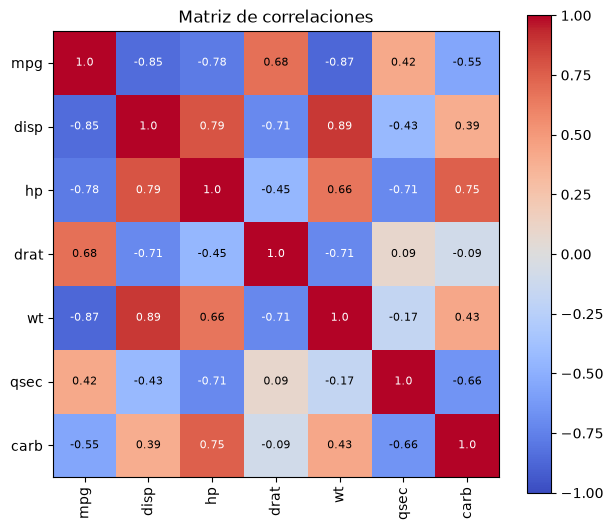

In [45]:
matriz = dp.plotCorrelation(ds, kind="correlation")

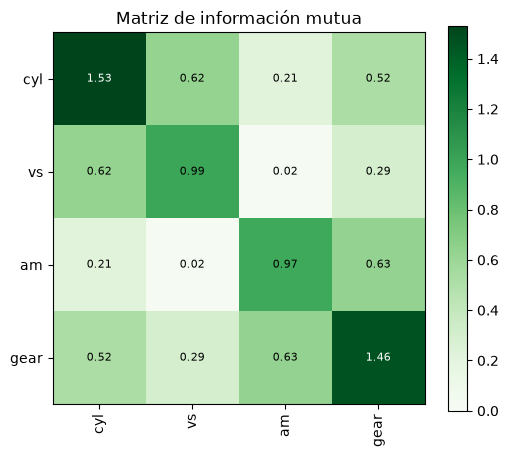

In [46]:
matriz = dp.plotCorrelation(ds, kind="mutual_information")

Si queremos ver la relación de las variables numéricas con la clase mediante la
información mutua, podemos discretizarlas antes. Así todas las variables son
categóricas:

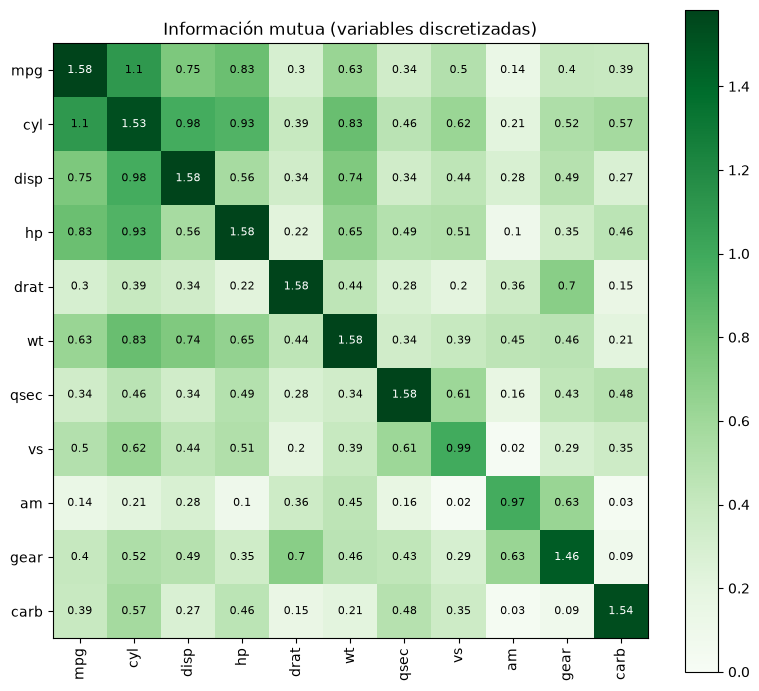

In [47]:
matriz = dp.plotCorrelation(ds_disc, kind="mutual_information",
                             title="Información mutua (variables discretizadas)")

## 8. Guardar y leer datasets en formato propio

Al guardar un dataset en un CSV se pierde parte de la información: qué
variables son categóricas (y sus categorías), cuál es la variable clase, etc.
Por eso el módulo incluye un formato de texto propio: `writeDataset` guarda
una cabecera con esa información y después los datos en formato CSV:

In [48]:
fichero_dts = os.path.join(tempfile.mkdtemp(), "coches.dts")
dp.writeDataset(ds, fichero_dts)

with open(fichero_dts, encoding="utf-8") as fichero:
    for linea in fichero.readlines()[:10]:
        print(linea, end="")

#Variables: 11
#Name: Coches (mtcars)
#Class: am
#Types: numeric,factor,numeric,integer,numeric,numeric,numeric,factor,factor,factor,integer
#Levels: cyl=4|6|8
#Levels: vs=0|1
#Levels: am=automatico|manual
#Levels: gear=3|4|5
mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
21.0,6,160.0,110,3.9,2.62,16.46,0,manual,4,4


`readDataset` lee el fichero y reconstruye el objeto `Dataset` con los mismos
tipos, categorías, variable clase y nombre:

In [49]:
ds_leido = dp.readDataset(fichero_dts)
print(ds_leido.name)
print(ds_leido.class_name)
print(list(ds_leido.data["am"].cat.categories))
print(ds_leido.data.equals(ds.data))

Coches (mtcars)
am
['automatico', 'manual']
True


El formato es exactamente el mismo que usa el paquete de R **dataprepR** (los
tipos se indican con los nombres de R: `numeric`, `integer`, `factor`,
`logical` y `character`). Así, un fichero guardado con `writeDataset` se puede
leer en R con `readDataset`, y un fichero guardado en R con `writeDataset` se
puede leer en Python con `readDataset`. Como el resto del paquete, el formato no
admite valores perdidos, así que al leer un fichero un texto como `"NA"` se
queda como texto.

## 9. Decisiones de diseño

Aquí recojo las decisiones de implementación que no son evidentes. Son las
mismas que en el paquete de R, así que los dos dan los mismos resultados.

**Discretización**

* Los intervalos son de la forma (a, b]: un valor igual a un punto de corte
  va al intervalo de su izquierda. El primero empieza en `-inf` y el último
  termina en `inf`, para poder discretizar valores nuevos fuera del rango
  original.
* En igual anchura, si la variable es constante la anchura es 0 y no se puede
  dividir el rango: se avisa y todos los valores quedan en un único
  intervalo, `(-inf, inf)`.
* En igual frecuencia el intervalo `i` termina en la posición
  `round(i * n / num_bins)` de los valores ordenados y el punto de corte se
  pone a mitad de camino entre ese valor y el siguiente.
* Un mismo valor no se puede repartir entre dos intervalos, así que un punto
  de corte solo se puede poner entre dos valores distintos. Si la posición
  calculada cae entre dos valores iguales, el corte se mueve al hueco entre
  valores distintos más cercano a la posición ideal (`i * n / num_bins`). Con
  valores repetidos las frecuencias pueden quedar algo descompensadas (como en
  `carb`, con 7, 13 y 12 coches), pero nunca queda ningún intervalo vacío. Si
  dos cortes acaban en el mismo hueco se quita uno y se avisa.
* En los nombres de los intervalos los límites se escriben con 4 cifras
  significativas para que se lean bien (por ejemplo, `(146.3, 240.7]`); los
  puntos de corte exactos son los que devuelven las funciones.

**Métricas**

* La entropía se mide en bits (`log2`) y se tienen en cuenta todas las
  categorías de la variable, aparezcan o no en los datos.
* La varianza y la desviación estándar son las muestrales (dividen entre
  `n - 1`), como `var` y `sd` en R. Las calculo con su fórmula, sin usar
  `np.var` ni `np.std` (que, además, por defecto dividen entre `n`).
* En el AUC, una fila se predice como positiva si su valor es mayor o igual
  que el punto de corte, y solo se usan como cortes los valores de los datos
  (son los únicos que cambian el TPR y el FPR). El área se calcula sumando
  trapecios (regla del trapecio).
* La clase positiva es `True` si la clase es booleana; en una variable
  categórica, la segunda categoría (en el orden de las categorías, como los
  niveles de un factor en R); y si no, el mayor de los dos valores (el 1 en
  una variable 0/1). Un AUC menor que 0.5 indica que los valores bajos de la
  variable se asocian a la clase positiva; para quedarse con esas variables
  al filtrar se usa `greater=False`.
* Un AUC cercano a 0.5 indica que ordenar por la variable no separa las
  clases, pero no que la variable no tenga ninguna relación con ellas: el AUC
  no detecta, por ejemplo, que los positivos estén en los dos extremos de la
  variable.
* Si la clase no es binaria, `computeMetrics` avisa y deja el AUC como `NaN`,
  pero calcula el resto de métricas.

**Filtrado**

* Por defecto, `filterData` devuelve solo las variables que cumplen el
  requisito, además de la variable clase, que se mantiene siempre. Con
  `keep_others=True` se conservan también las variables a las que no se
  aplica la métrica, lo que permite encadenar filtros sobre métricas
  distintas.
* Si ninguna variable cumple el requisito, el resultado solo tiene la variable
  clase, y sus métricas (`computeMetrics` o `summary`) son una tabla sin filas.

**Tipos de variables**

* Son numéricas las variables enteras y reales, y categóricas las de tipo
  `category` y las booleanas. Las de texto no se consideran categóricas
  porque suelen ser nombres o identificadores; `readCSV` ya convierte en
  categóricas las columnas con pocos valores distintos.
* Las funciones usan el tipo que tiene cada columna, no lo que significa: una
  categoría codificada con números se trata como numérica hasta que se
  convierte con `astype("category")` (ver el apartado 1). La regla de
  `readCSV` es aproximada, así que a veces hay que corregir el tipo a mano.
* La correlación y la información mutua tienen escalas distintas, así que
  `computeCorrelations` devuelve dos matrices. Los pares de una variable
  numérica y otra categórica no se comparan; para relacionarlas se puede
  discretizar antes la numérica (como en el apartado 7).

**Sobre el código en Python**

* En lugar de la clase S3 de R uso una clase de Python, `Dataset`. Las
  funciones comprueban con `isinstance` si reciben un `Dataset` y, en ese
  caso, tienen en cuenta su variable clase.
* Las funciones no modifican los datos que reciben, trabajan sobre una copia.
  En R esto pasa solo, pero en Python un `DataFrame` se pasa por referencia,
  así que hay que hacer la copia a mano.
* Las funciones que devuelven dos cosas (por ejemplo los valores
  discretizados y los puntos de corte) devuelven una tupla.
* Para simplificar, el paquete no admite valores perdidos (`NaN`) ni
  infinitos: las funciones dan un error si los encuentran en los datos que
  tienen que usar (por ejemplo, en una variable numérica o en la variable
  clase), y `writeDataset` no guarda datos con valores perdidos. Así, un `NaN`
  en la tabla de métricas indica que esa métrica no se aplica a la variable,
  salvo en un caso: con una sola observación la varianza muestral no está
  definida (necesita al menos dos valores) y también vale `NaN`.
* Todos los algoritmos están implementados a mano (con `np.sort`,
  `np.unique`, `np.sum`, bucles...), sin usar funciones que ya los resuelvan
  como `pd.cut`, `pd.qcut`, `np.var`, `np.corrcoef` o `value_counts`. En este
  notebook `np.corrcoef` y `value_counts` solo se usan para comprobar o
  mostrar resultados.
* El formato propio de ficheros es el mismo que el del paquete de R, así que
  los datasets se pueden pasar de un lenguaje a otro.

## 10. Resumen

Un flujo de trabajo típico con el módulo sería:

In [50]:
datos = dp.Dataset(dp.readCSV("mtcars.csv"), class_name="am")
datos = dp.standardizeData(datos)
datos = dp.filterData(datos, metric="auc", threshold=0.75)
dp.computeMetrics(datos)

,type,variance,auc,entropy
mpg,numeric,1.0,0.8300,NaN
drat,numeric,1.0,0.9028,NaN


Todas las funciones tienen su documentación con la descripción de los
argumentos, lo que devuelven, los detalles del método y ejemplos de uso. Se
consulta con `help`, por ejemplo:

In [51]:
help(dp.entropy)

Help on function entropy in module dataprepy.metrics:

entropy(x)
    Entropía (en bits) de una variable categórica.

    Parameters
    ----------
    x : pandas.Categorical o pandas.Series de tipo category
        Valores de la variable.

    Returns
    -------
    float
        Entropía. Vale 0 si la variable siempre toma el mismo valor y como
        máximo log2(k), siendo k el número de categorías.

    Notes
    -----
    Primero se estima la probabilidad de cada posible valor (cada categoría,
    aparezca o no en los datos) como el número de apariciones dividido entre
    el total de valores. Después se aplica H(X) = sum(-p_i * log2(p_i)), sin
    contar los valores con probabilidad 0.

    Por ejemplo, con los valores posibles a, b y c y los datos
    (a, a, c, c, c), las probabilidades son 0.4, 0 y 0.6 y la entropía es
    -0.4 * log2(0.4) - 0.6 * log2(0.6) = 0.971.

    Examples
    --------
    >>> x = pd.Categorical(["a", "a", "c", "c", "c"], categories=["a", "b", "c"])
  

La documentación general del módulo, con la lista de todas las funciones, se
consulta con `help(dp)`.